# Análisis de resultados · Laboratorio 02

Lee lo que genera `python main.py experimentos` y responde las 5 preguntas de la diapositiva 66:

1. ¿Más varianza retenida produce mayor macro-F1?
2. ¿Fisherfaces mejora a PCA en ambas bases?
3. ¿Qué dimensión equilibra calidad y costo?
4. ¿Los tres clasificadores confunden las mismas identidades?
5. ¿Qué muestra el mapa 2D y qué demuestra TEST?

Antes de ejecutar: `conda activate lab-embeddings-faciales` y `python main.py experimentos` desde la raíz. Se usa el mismo split del proyecto (semilla 42, 25 % de prueba); TEST no se usa para elegir nada.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import DIMENSIONES, DIR_FIGURAS, DIR_RESULTADOS, RANDOM_STATE, ruta_modelo
from src.datos.division import DivisorEstratificado
from src.datos.lfw import CargadorLFW
from src.datos.olivetti import CargadorOlivetti
from src.embeddings.pca import ExtractorPCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110
ORDEN_EMB = ["pca", "lda", "fisherfaces"]
ORDEN_MOD = ["svm", "knn", "arbol"]
print("Proyecto:", RAIZ.name)

Proyecto: ML-LAB02


## 1. Datos y partición

N, C, H y W de cada base (diapositiva 6).

In [2]:
divisor = DivisorEstratificado()
conjuntos = {"olivetti": CargadorOlivetti().cargar(), "lfw": CargadorLFW().cargar()}
particiones = {k: divisor.dividir(v) for k, v in conjuntos.items()}

resumen = []
for nombre, c in conjuntos.items():
    p = particiones[nombre]
    _, conteos = np.unique(c.y, return_counts=True)
    resumen.append({
        "dataset": nombre, "N": c.X.shape[0], "C": c.n_clases, "H": c.alto, "W": c.ancho,
        "p": c.X.shape[1], "N_train": p.X_train.shape[0], "N_test": p.X_test.shape[0],
        "fotos/clase min": conteos.min(), "fotos/clase max": conteos.max(),
        "rango X": f"[{c.X.min():.2f}, {c.X.max():.2f}]",
    })
tabla_datos = pd.DataFrame(resumen).set_index("dataset")
tabla_datos

,N,C,H,W,p,N_train,N_test,fotos/clase min,fotos/clase max,rango X
dataset,,,,,,,,,,
olivetti,400,40,64,64,4096,300,100,10,10,"[0.00, 1.00]"
lfw,2773,50,62,47,2914,2079,694,22,530,"[0.00, 1.00]"


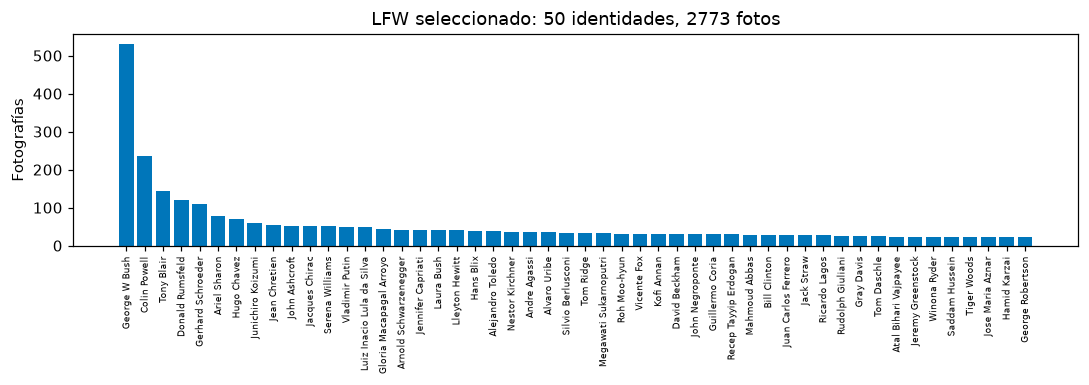

Las 5 identidades más frecuentes: [('George W Bush', 530), ('Colin Powell', 236), ('Tony Blair', 144), ('Donald Rumsfeld', 121), ('Gerhard Schroeder', 109)]


In [3]:
lfw = conjuntos["lfw"]
ids, conteos = np.unique(lfw.y, return_counts=True)
orden = np.argsort(conteos)[::-1]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(ids)), conteos[orden], color="#0076BA")
ax.set_xticks(range(len(ids)))
ax.set_xticklabels([lfw.nombres_identidades[i] for i in ids[orden]], rotation=90, fontsize=6)
ax.set_ylabel("Fotografías")
ax.set_title(f"LFW seleccionado: {lfw.n_clases} identidades, {lfw.X.shape[0]} fotos")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "analisis_lfw_clases.png", dpi=150)
plt.show()
print("Las 5 identidades más frecuentes:", [(lfw.nombres_identidades[i], int(conteos[i])) for i in ids[orden][:5]])

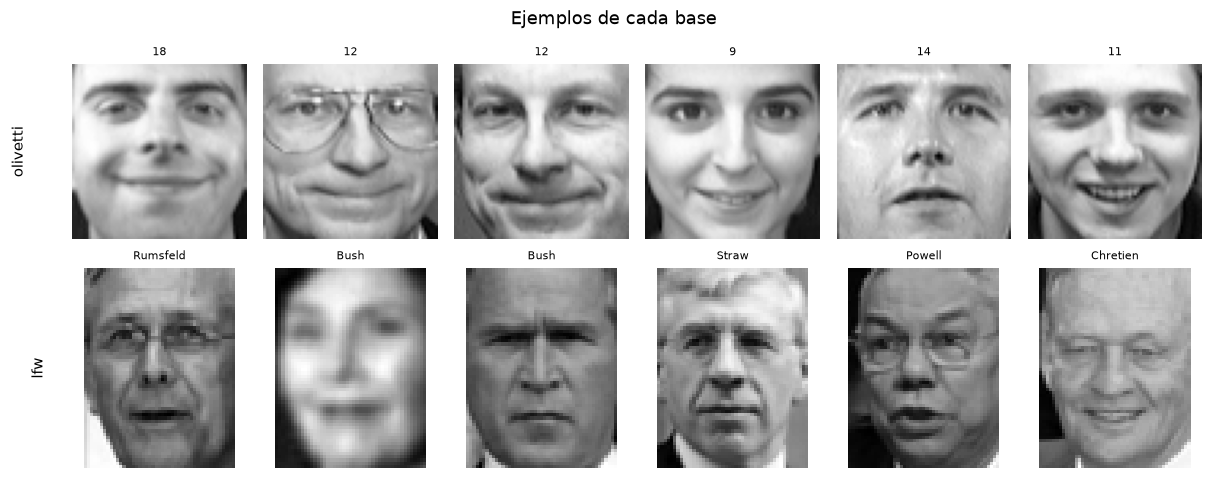

In [4]:
fig, ejes = plt.subplots(2, 6, figsize=(11, 4.4))
for fila, nombre in enumerate(["olivetti", "lfw"]):
    c = conjuntos[nombre]
    rng = np.random.default_rng(RANDOM_STATE)
    for ax, i in zip(ejes[fila], rng.choice(c.X.shape[0], 6, replace=False)):
        ax.imshow(c.images[i], cmap="gray")
        ax.set_title(c.nombres_identidades[c.y[i]].split()[-1][:14], fontsize=7)
        ax.axis("off")
    ejes[fila][0].text(-0.35, 0.5, nombre, transform=ejes[fila][0].transAxes, rotation=90, va="center")
fig.suptitle("Ejemplos de cada base")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "analisis_ejemplos.png", dpi=150)
plt.show()

## 2. Resultados por dataset

Una fila por representación × d × clasificador. El tiempo es `fit + predict` del clasificador; no incluye el ajuste del embedding.

In [5]:
res = pd.read_csv(DIR_RESULTADOS / "resultados_modelos.csv")
res["embedding"] = pd.Categorical(res["embedding"], ORDEN_EMB, ordered=True)
res["modelo"] = pd.Categorical(res["modelo"], ORDEN_MOD, ordered=True)
res = res.sort_values(["dataset", "embedding", "d", "modelo"]).reset_index(drop=True)
print(res.groupby("dataset", observed=True).size().rename("filas"))
res.head()

dataset
lfw         27
olivetti    27
Name: filas, dtype: int64


,dataset,embedding,d,modelo,parametros,accuracy,macro_f1,tiempo_s
0,lfw,pca,10,svm,"kernel=linear, C=1.0, probability=True",0.330,0.173,2.159
1,lfw,pca,10,knn,"n_neighbors=3, metric=euclidean",0.192,0.126,0.011
2,lfw,pca,10,arbol,"max_depth=8, criterion=gini",0.222,0.065,0.020
3,lfw,pca,20,svm,"kernel=linear, C=1.0, probability=True",0.441,0.322,2.013
4,lfw,pca,20,knn,"n_neighbors=3, metric=euclidean",0.233,0.150,0.004


In [6]:
def tabla_ancha(dataset, metrica):
    t = res[res["dataset"] == dataset].pivot_table(
        index=["embedding", "d"], columns="modelo", values=metrica, observed=True)
    return t[ORDEN_MOD]

for dataset in ["olivetti", "lfw"]:
    for metrica in ["accuracy", "macro_f1"]:
        print(f"\n== {dataset} · {metrica} ==")
        display(tabla_ancha(dataset, metrica).style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))


== olivetti · accuracy ==



== olivetti · macro_f1 ==



== lfw · accuracy ==



== lfw · macro_f1 ==


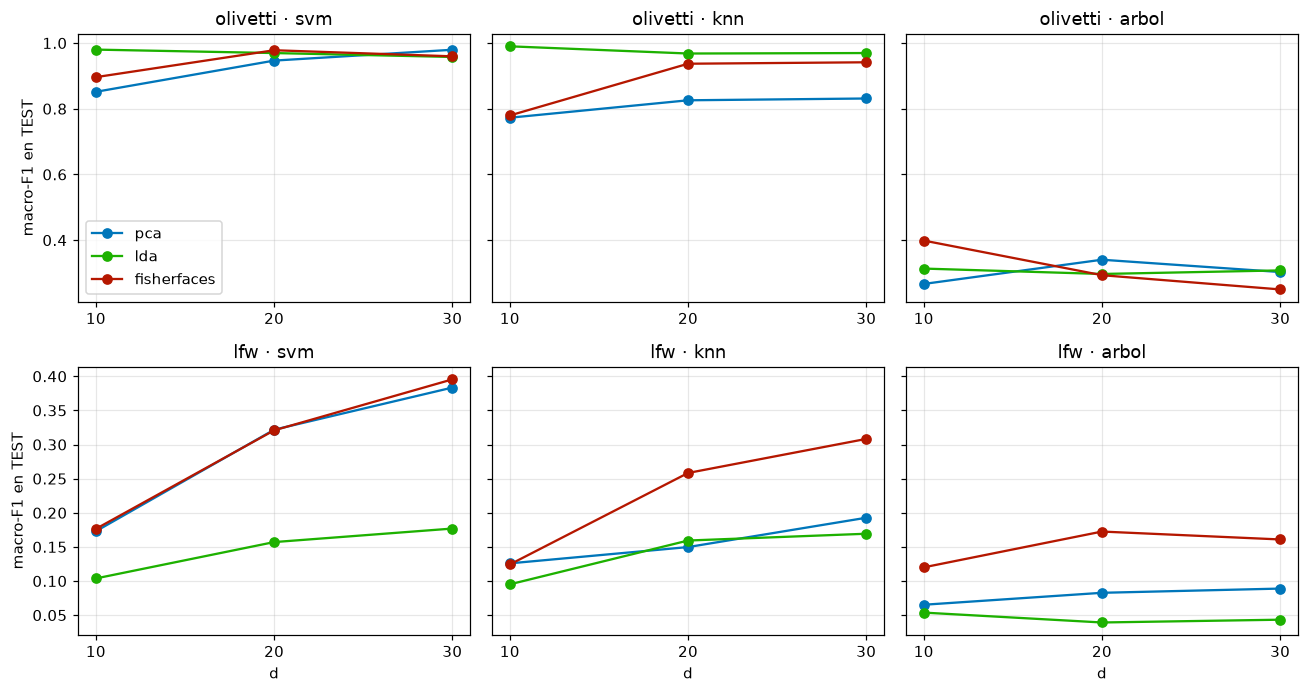

In [7]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 6.4), sharey="row")
colores = {"pca": "#0076BA", "lda": "#1DB100", "fisherfaces": "#B51700"}
for fila, dataset in enumerate(["olivetti", "lfw"]):
    for col, modelo in enumerate(ORDEN_MOD):
        ax = ejes[fila, col]
        sub = res[(res["dataset"] == dataset) & (res["modelo"] == modelo)]
        for emb in ORDEN_EMB:
            s = sub[sub["embedding"] == emb].sort_values("d")
            ax.plot(s["d"], s["macro_f1"], marker="o", label=emb, color=colores[emb])
        ax.set_title(f"{dataset} · {modelo}")
        ax.set_xticks(list(DIMENSIONES))
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("macro-F1 en TEST")
        if fila == 1:
            ax.set_xlabel("d")
ejes[0, 0].legend()
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "analisis_macro_f1_vs_d.png", dpi=150)
plt.show()

## 3. Pregunta 1 · Varianza retenida y macro-F1

Varianza acumulada de PCA (ajustado en TRAIN) en d = 10, 20, 30 junto al macro-F1 de PCA.

In [8]:
filas = []
for dataset, p in particiones.items():
    pca = ExtractorPCA(n_components=max(DIMENSIONES)).fit(p.X_train)
    acum = pca.varianza_acumulada()
    for d in DIMENSIONES:
        for modelo in ORDEN_MOD:
            fila = res[(res.dataset == dataset) & (res.embedding == "pca") & (res.d == d) & (res.modelo == modelo)]
            filas.append({"dataset": dataset, "d": d, "varianza_retenida": acum[d - 1],
                          "modelo": modelo, "macro_f1": float(fila["macro_f1"].iloc[0])})
var_f1 = pd.DataFrame(filas)
var_f1.pivot_table(index=["dataset", "d", "varianza_retenida"], columns="modelo", values="macro_f1")[ORDEN_MOD]

modelo                           svm    knn  arbol
dataset  d  varianza_retenida                     
lfw      10 0.623              0.173  0.126  0.065
         20 0.724              0.322  0.150  0.083
         30 0.775              0.383  0.193  0.089
olivetti 10 0.655              0.852  0.773  0.267
         20 0.765              0.947  0.826  0.340
         30 0.822              0.980  0.831  0.303

## 4. Pregunta 2 · ¿Fisherfaces mejora a PCA?

Diferencia de macro-F1 (Fisherfaces − PCA) con el mismo d y clasificador. Positivo: gana Fisherfaces.

In [9]:
pca_t = res[res.embedding == "pca"].set_index(["dataset", "d", "modelo"])["macro_f1"]
fis_t = res[res.embedding == "fisherfaces"].set_index(["dataset", "d", "modelo"])["macro_f1"]
lda_t = res[res.embedding == "lda"].set_index(["dataset", "d", "modelo"])["macro_f1"]
delta = (fis_t - pca_t).rename("Δ macro-F1 (Fisher − PCA)").reset_index()
delta.pivot_table(index=["dataset", "d"], columns="modelo", values="Δ macro-F1 (Fisher − PCA)", observed=True)[ORDEN_MOD].style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.6, vmax=0.6)

In [10]:
# LDA directo sobre píxeles frente a Fisherfaces (misma d).
comp = pd.concat([lda_t.rename("lda"), fis_t.rename("fisherfaces")], axis=1).dropna()
comp["Δ (Fisher − LDA)"] = comp["fisherfaces"] - comp["lda"]
comp.unstack("modelo").round(3)

lda               fisherfaces               Δ (Fisher − LDA)  \
modelo         svm    knn  arbol         svm    knn  arbol              svm   
dataset  d                                                                    
lfw      10  0.104  0.095  0.054       0.176  0.124  0.120            0.073   
         20  0.157  0.159  0.039       0.321  0.258  0.172            0.164   
         30  0.177  0.169  0.043       0.395  0.308  0.161            0.219   
olivetti 10  0.980  0.990  0.314       0.896  0.780  0.399           -0.084   
         20  0.970  0.968  0.297       0.978  0.937  0.293            0.009   
         30  0.958  0.970  0.308       0.960  0.941  0.250            0.002   

                           
modelo         knn  arbol  
dataset  d                 
lfw      10  0.029  0.066  
         20  0.099  0.133  
         30  0.139  0.118  
olivetti 10 -0.210  0.085  
         20 -0.031 -0.004  
         30 -0.028 -0.058

## 5. Pregunta 3 · Calidad y costo

Costo = tiempo del clasificador y d (números por foto). El borde negro marca la frontera de Pareto: ninguna otra configuración tiene más macro-F1 con menos tiempo.

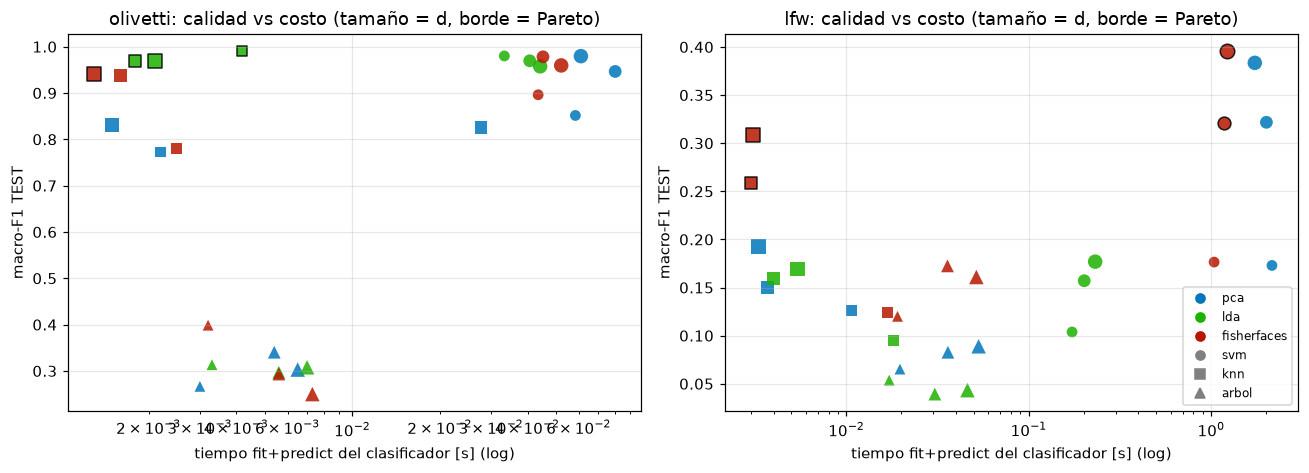

,dataset,embedding,d,modelo,accuracy,macro_f1,tiempo_s
52,olivetti,fisherfaces,30,knn,0.950,0.941,0.001
40,olivetti,lda,20,knn,0.970,0.968,0.002
43,olivetti,lda,30,knn,0.970,0.970,0.002
37,olivetti,lda,10,knn,0.990,0.990,0.004
22,lfw,fisherfaces,20,knn,0.344,0.258,0.003
25,lfw,fisherfaces,30,knn,0.402,0.308,0.003
21,lfw,fisherfaces,20,svm,0.438,0.321,1.176
24,lfw,fisherfaces,30,svm,0.484,0.395,1.228


In [11]:
def pareto(df):
    df = df.sort_values(["tiempo_s", "macro_f1"], ascending=[True, False])
    mejor, marcas = -1.0, []
    for f1 in df["macro_f1"]:
        marcas.append(f1 > mejor)
        mejor = max(mejor, f1)
    return df.assign(pareto=marcas)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4))
marcadores = {"svm": "o", "knn": "s", "arbol": "^"}
fronteras = []
for ax, dataset in zip(ejes, ["olivetti", "lfw"]):
    sub = pareto(res[res.dataset == dataset])
    fronteras.append(sub[sub.pareto])
    for _, f in sub.iterrows():
        ax.scatter(f.tiempo_s, f.macro_f1, color=colores[f.embedding], marker=marcadores[f.modelo],
                   s=30 + 2 * f.d, edgecolor="k" if f.pareto else "none", alpha=0.85)
    ax.set_xscale("log")
    ax.set_xlabel("tiempo fit+predict del clasificador [s] (log)")
    ax.set_ylabel("macro-F1 TEST")
    ax.set_title(f"{dataset}: calidad vs costo (tamaño = d, borde = Pareto)")
    ax.grid(alpha=0.3)
from matplotlib.lines import Line2D
leyenda = [Line2D([], [], color=c, marker="o", ls="", label=e) for e, c in colores.items()]
leyenda += [Line2D([], [], color="gray", marker=m, ls="", label=k) for k, m in marcadores.items()]
ejes[1].legend(handles=leyenda, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "analisis_calidad_costo.png", dpi=150)
plt.show()
pd.concat(fronteras)[["dataset", "embedding", "d", "modelo", "accuracy", "macro_f1", "tiempo_s"]]

In [12]:
res.groupby(["dataset", "modelo"], observed=True)["tiempo_s"].agg(["mean", "min", "max"]).round(4)

mean    min    max
dataset  modelo                     
lfw      svm     1.107  0.173  2.159
         knn     0.008  0.003  0.018
         arbol   0.034  0.017  0.053
olivetti svm     0.051  0.033  0.080
         knn     0.005  0.001  0.028
         arbol   0.005  0.003  0.007

## 6. Pregunta 4 · ¿Se confunden las mismas identidades?

Se cargan los modelos de `data/modelos/` y se comparan las fotos de TEST que falla cada clasificador, con d = 20.

In [13]:
def predicciones(dataset, embedding, modelo, d):
    bundle = joblib.load(ruta_modelo(dataset, embedding, modelo, d))
    p = particiones[dataset]
    return bundle["clasificador"].predict(bundle["extractor"].transform(p.X_test))

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 1.0

D = 20
filas, errores = [], {}
for dataset in ["olivetti", "lfw"]:
    y_te = particiones[dataset].y_test
    for emb in ORDEN_EMB:
        for modelo in ORDEN_MOD:
            pred = predicciones(dataset, emb, modelo, D)
            errores[(dataset, emb, modelo)] = set(np.flatnonzero(pred != y_te))
        e = [errores[(dataset, emb, m)] for m in ORDEN_MOD]
        filas.append({
            "dataset": dataset, "embedding": emb,
            **{f"errores {m}": len(x) for m, x in zip(ORDEN_MOD, e)},
            "comunes a los 3": len(e[0] & e[1] & e[2]),
            "J(svm,knn)": jaccard(e[0], e[1]), "J(svm,arbol)": jaccard(e[0], e[2]), "J(knn,arbol)": jaccard(e[1], e[2]),
        })
solap = pd.DataFrame(filas).set_index(["dataset", "embedding"])
solap.round(2)

errores svm  errores knn  errores arbol  \
dataset  embedding                                              
olivetti pca                    5           17             64   
         lda                    3            3             70   
         fisherfaces            2            5             63   
lfw      pca                  388          532            549   
         lda                  542          523            621   
         fisherfaces          390          455            478   

                      comunes a los 3  J(svm,knn)  J(svm,arbol)  J(knn,arbol)  
dataset  embedding                                                             
olivetti pca                        3        0.22          0.06          0.17  
         lda                        3        1.00          0.04          0.04  
         fisherfaces                1        0.17          0.03          0.08  
lfw      pca                      311        0.59          0.60          0.70  
         lda                      477        0.88          0.80          0.77  
         fisherfaces              297        0.64          0.64          0.65

In [14]:
from collections import Counter

def pares_confundidos(dataset, emb, modelo, k=5):
    y_te = particiones[dataset].y_test
    pred = predicciones(dataset, emb, modelo, D)
    nombres = conjuntos[dataset].nombres_identidades
    cont = Counter((nombres[r], nombres[q]) for r, q in zip(y_te, pred) if r != q)
    return cont.most_common(k)

for dataset in ["olivetti", "lfw"]:
    for modelo in ORDEN_MOD:
        print(f"{dataset} · fisherfaces d={D} · {modelo}: {pares_confundidos(dataset, 'fisherfaces', modelo)}")

olivetti · fisherfaces d=20 · svm: [(('Identidad 2', 'Identidad 37'), 1), (('Identidad 9', 'Identidad 7'), 1)]
olivetti · fisherfaces d=20 · knn: [(('Identidad 19', 'Identidad 8'), 1), (('Identidad 16', 'Identidad 12'), 1), (('Identidad 15', 'Identidad 18'), 1), (('Identidad 0', 'Identidad 15'), 1), (('Identidad 9', 'Identidad 7'), 1)]
olivetti · fisherfaces d=20 · arbol: [(('Identidad 20', 'Identidad 15'), 3), (('Identidad 38', 'Identidad 21'), 3), (('Identidad 23', 'Identidad 15'), 3), (('Identidad 28', 'Identidad 21'), 3), (('Identidad 30', 'Identidad 15'), 3)]
lfw · fisherfaces d=20 · svm: [(('Colin Powell', 'George W Bush'), 11), (('Gerhard Schroeder', 'George W Bush'), 7), (('John Ashcroft', 'George W Bush'), 7), (('Tony Blair', 'Gerhard Schroeder'), 7), (('David Beckham', 'George W Bush'), 7)]
lfw · fisherfaces d=20 · knn: [(('George W Bush', 'Colin Powell'), 18), (('Tony Blair', 'George W Bush'), 11), (('George W Bush', 'Donald Rumsfeld'), 10), (('Colin Powell', 'George W Bush'

In [15]:
from sklearn.metrics import f1_score

# F1 por identidad en LFW (Fisherfaces d=20, SVM): ¿el desbalance afecta?
dataset, emb, modelo = "lfw", "fisherfaces", "svm"
p = particiones[dataset]
pred = predicciones(dataset, emb, modelo, D)
f1c = f1_score(p.y_test, pred, average=None, labels=np.unique(p.y_train))
_, n_train = np.unique(p.y_train, return_counts=True)
por_clase = pd.DataFrame({"identidad": conjuntos[dataset].nombres_identidades, "fotos_train": n_train, "F1": f1c})
print("Correlación de Spearman (fotos en TRAIN vs F1):", round(por_clase[["fotos_train", "F1"]].corr("spearman").iloc[0, 1], 3))
pd.concat([por_clase.nlargest(5, "F1"), por_clase.nsmallest(5, "F1")])

Correlación de Spearman (fotos en TRAIN vs F1): 0.355


,identidad,fotos_train,F1
40,Saddam Hussein,17,0.800
13,Gloria Macapagal Arroyo,33,0.783
30,Laura Bush,31,0.762
21,Jean Chretien,41,0.667
41,Serena Williams,39,0.667
6,Bill Clinton,22,0.000
8,David Beckham,23,0.000
14,Gray Davis,19,0.000
19,Jack Straw,21,0.000
23,Jeremy Greenstock,18,0.000


### Errores concretos

Arriba, la foto de TEST mal clasificada; abajo, una foto de TRAIN de la identidad predicha.

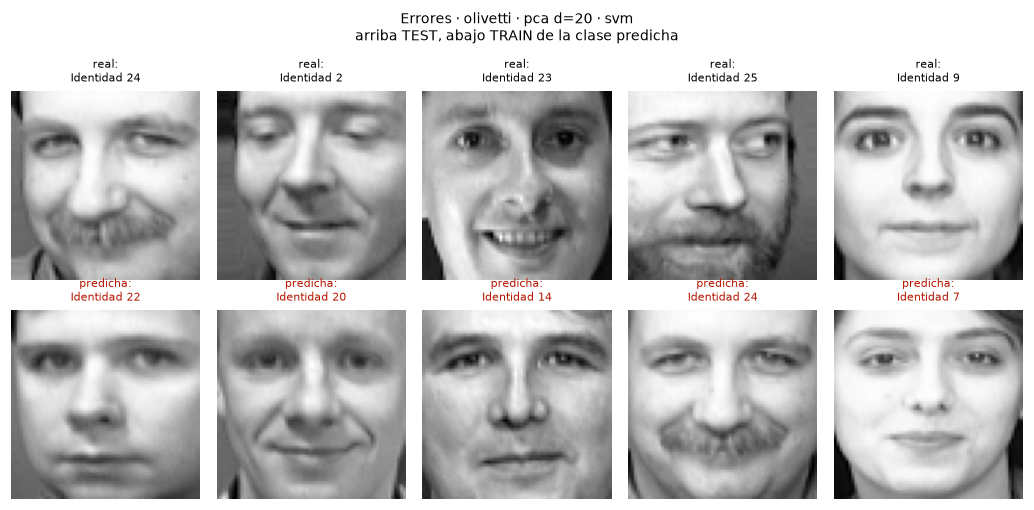

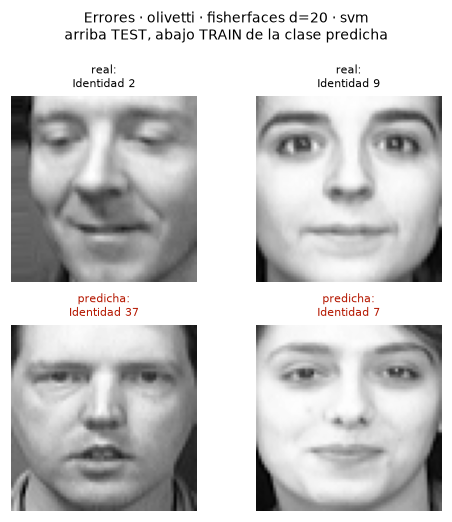

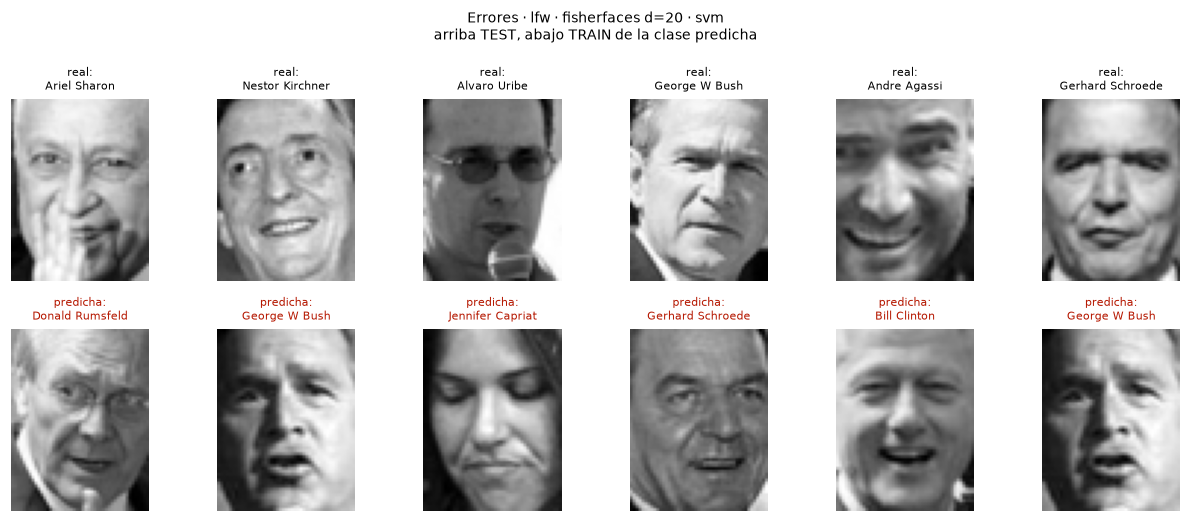

In [16]:
def galeria_errores(dataset, emb, modelo, d=D, n=6):
    p = particiones[dataset]
    nombres = conjuntos[dataset].nombres_identidades
    pred = predicciones(dataset, emb, modelo, d)
    malos = np.flatnonzero(pred != p.y_test)[:n]
    if malos.size == 0:
        print(f"{dataset} · {emb} · {modelo}: sin errores en TEST")
        return None
    fig, ejes = plt.subplots(2, malos.size, figsize=(max(1.9 * malos.size, 4.6), 4.8), squeeze=False)
    for j, i in enumerate(malos):
        ejes[0, j].imshow(p.images_test[i], cmap="gray")
        ejes[0, j].set_title(f"real:\n{nombres[p.y_test[i]][:16]}", fontsize=7)
        ref = np.flatnonzero(p.y_train == pred[i])[0]
        ejes[1, j].imshow(p.images_train[ref], cmap="gray")
        ejes[1, j].set_title(f"predicha:\n{nombres[pred[i]][:16]}", fontsize=7, color="#B51700")
        for ax in ejes[:, j]:
            ax.axis("off")
    fig.suptitle(f"Errores · {dataset} · {emb} d={d} · {modelo}\narriba TEST, abajo TRAIN de la clase predicha", fontsize=9)
    fig.tight_layout()
    ruta = DIR_FIGURAS / f"analisis_errores_{dataset}_{emb}_{modelo}.png"
    fig.savefig(ruta, dpi=150)
    plt.show()
    return ruta

galeria_errores("olivetti", "pca", "svm")
galeria_errores("olivetti", "fisherfaces", "svm")
_ = galeria_errores("lfw", "fisherfaces", "svm")

## 7. Pregunta 5 · Mapa 2D y TEST

Los mapas usan `Z_train` (d = 20, semilla 42) y muestran vecindades de TRAIN. El macro-F1 en TEST es lo que mide reconocimiento.

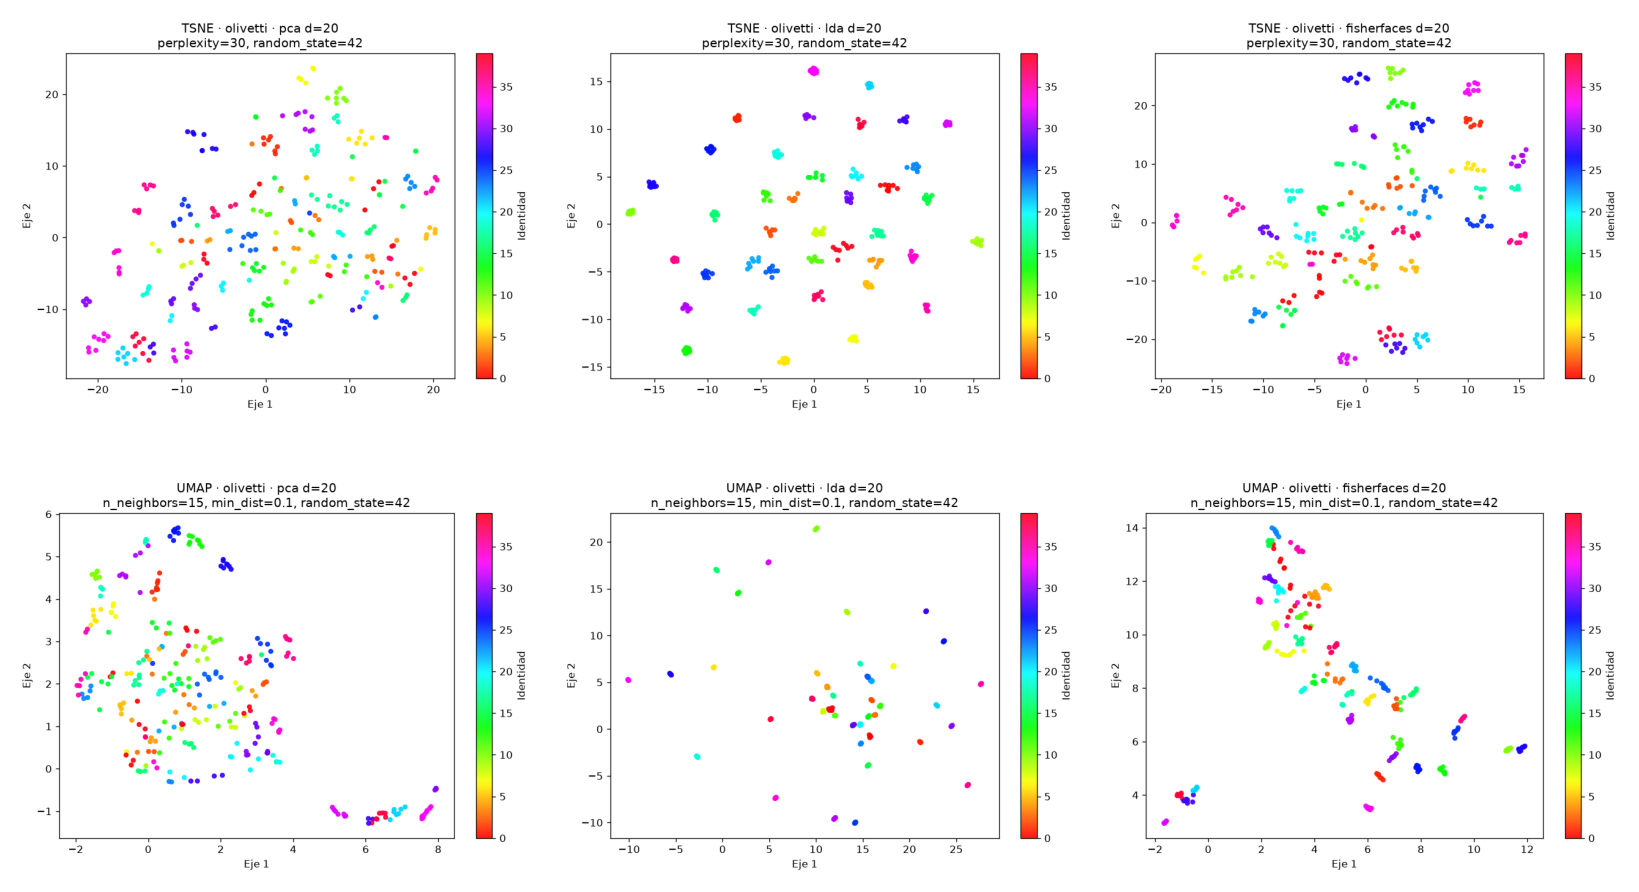

modelo,svm,knn,arbol
embedding,,,
pca,0.947,0.826,0.340
lda,0.970,0.968,0.297
fisherfaces,0.978,0.937,0.293


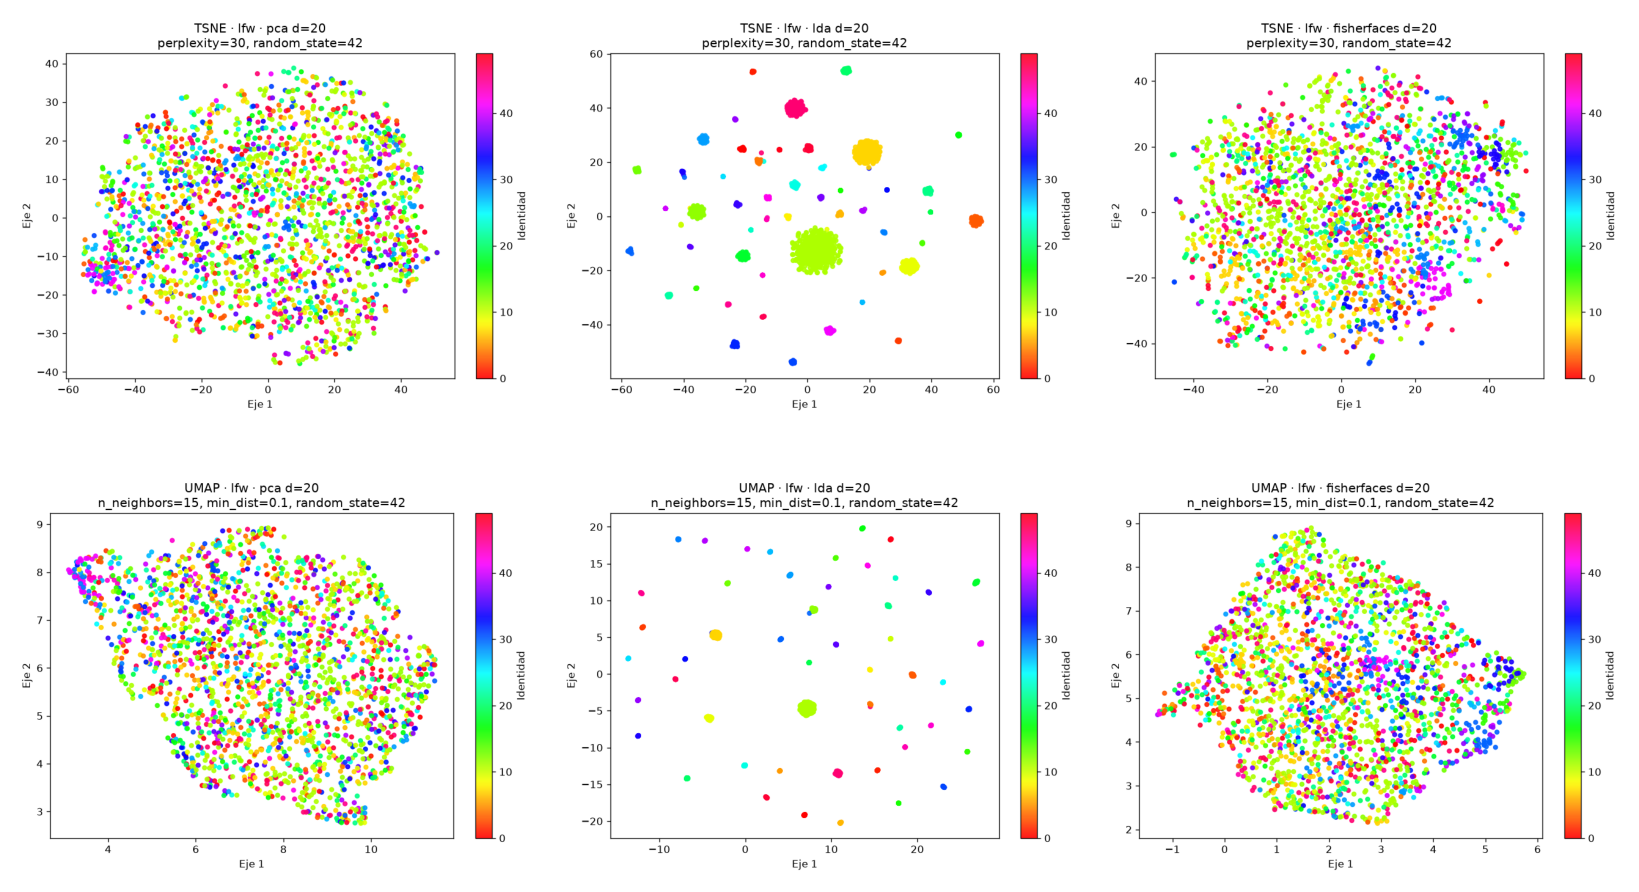

modelo,svm,knn,arbol
embedding,,,
pca,0.322,0.150,0.083
lda,0.157,0.159,0.039
fisherfaces,0.321,0.258,0.172


In [17]:
for dataset in ["olivetti", "lfw"]:
    fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
    for fila, metodo in enumerate(["tsne", "umap"]):
        for col, emb in enumerate(ORDEN_EMB):
            ruta = DIR_FIGURAS / f"{metodo}_{dataset}_{emb}_d20.png"
            ejes[fila, col].imshow(plt.imread(ruta))
            ejes[fila, col].axis("off")
    fig.tight_layout()
    plt.show()
    f1 = res[(res.dataset == dataset) & (res.d == 20)].pivot_table(index="embedding", columns="modelo", values="macro_f1", observed=True)
    display(f1[ORDEN_MOD].round(3))

In [18]:
# Medida cuantitativa del mapa: ¿qué fracción de los 5 vecinos de TRAIN comparte identidad?
from sklearn.neighbors import NearestNeighbors

def pureza_vecindad(Z, y, k=5):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return float((y[idx] == y[:, None]).mean())

filas = []
for dataset in ["olivetti", "lfw"]:
    p = particiones[dataset]
    for emb in ORDEN_EMB:
        bundle = joblib.load(ruta_modelo(dataset, emb, "knn", 20))
        Z_tr = bundle["extractor"].transform(p.X_train)
        Z_te = bundle["extractor"].transform(p.X_test)
        knn_te = NearestNeighbors(n_neighbors=5).fit(Z_tr).kneighbors(Z_te, return_distance=False)
        filas.append({"dataset": dataset, "embedding": emb,
                      "pureza 5-NN en TRAIN": pureza_vecindad(Z_tr, p.y_train),
                      "pureza 5-NN TEST→TRAIN": float((p.y_train[knn_te] == p.y_test[:, None]).mean())})
pd.DataFrame(filas).set_index(["dataset", "embedding"]).round(3)

pureza 5-NN en TRAIN  pureza 5-NN TEST→TRAIN
dataset  embedding                                                
olivetti pca                         0.613                   0.638
         lda                         0.991                   0.956
         fisherfaces                 0.875                   0.864
lfw      pca                         0.180                   0.187
         lda                         0.997                   0.238
         fisherfaces                 0.271                   0.255

## 8. Eigenfaces, fisherfaces y reconstrucción

PCA aprende patrones de variación y Fisherfaces, patrones que separan identidades. La reconstrucción sigue el notebook `Olivetti_PCA_proyeccion_y_reconstruccion.ipynb` del docente.

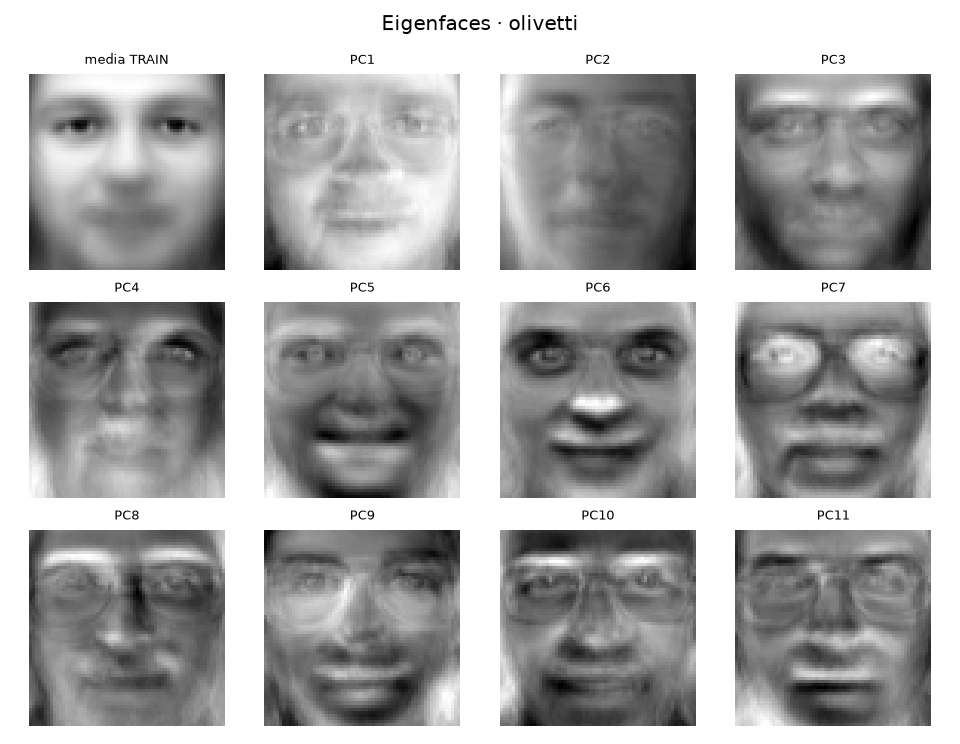

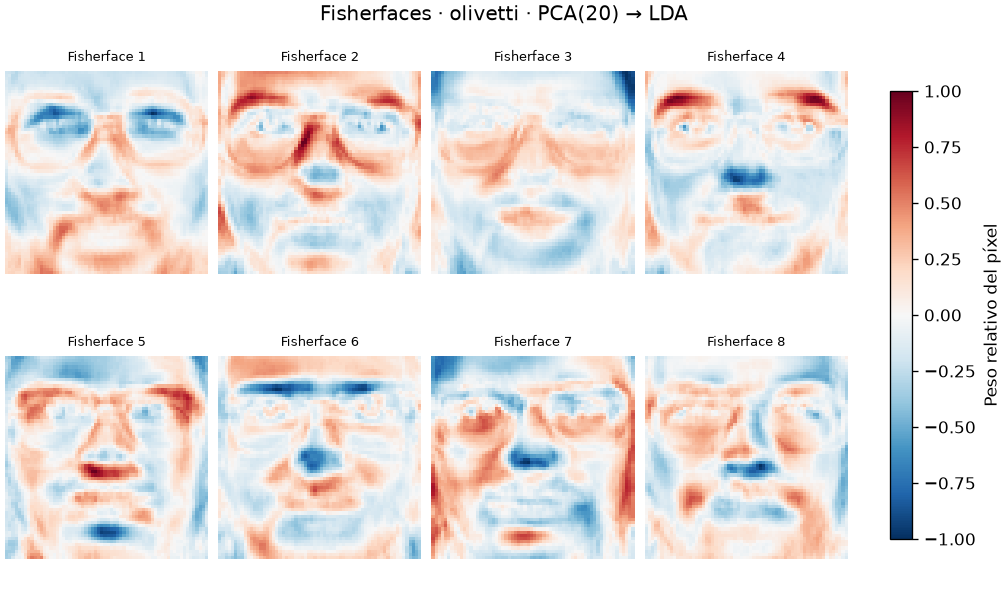

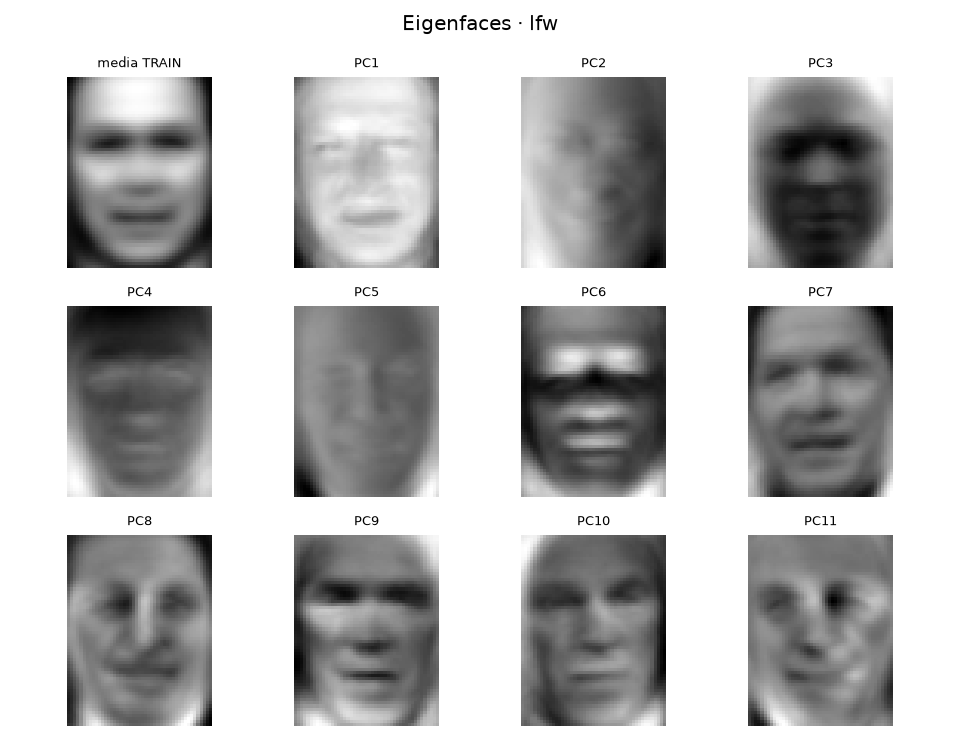

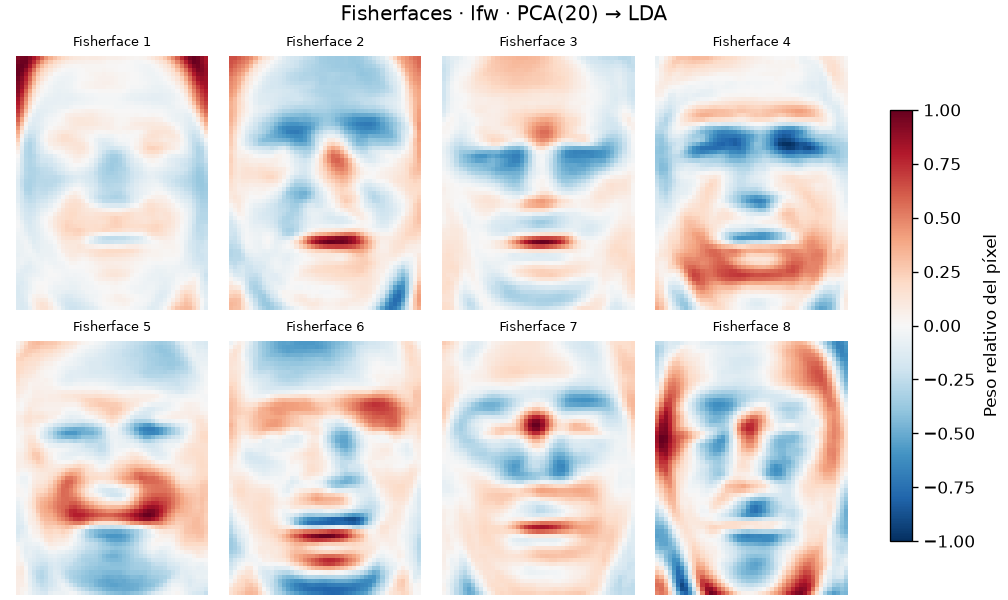

In [19]:
for nombre in ["eigenfaces_olivetti.png", "fisherfaces_olivetti.png", "eigenfaces_lfw.png", "fisherfaces_lfw.png"]:
    display(Image(filename=str(DIR_FIGURAS / nombre), width=620))

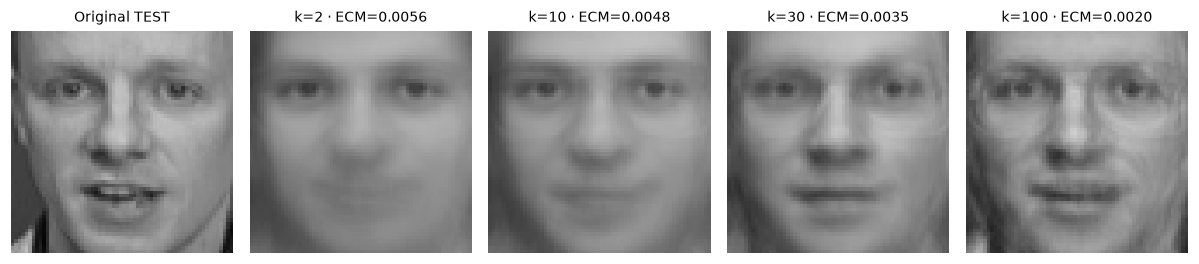

In [20]:
from sklearn.decomposition import PCA

p = particiones["olivetti"]
pca100 = PCA(n_components=100, svd_solver="full", random_state=RANDOM_STATE).fit(p.X_train)
z = pca100.transform(p.X_test[:1])[0]
fig, ejes = plt.subplots(1, 5, figsize=(11, 2.6))
ejes[0].imshow(p.images_test[0], cmap="gray", vmin=0, vmax=1)
ejes[0].set_title("Original TEST", fontsize=9)
for ax, k in zip(ejes[1:], [2, 10, 30, 100]):
    rec = pca100.mean_ + z[:k] @ pca100.components_[:k]
    ecm = np.mean((p.X_test[0] - rec) ** 2)
    ax.imshow(rec.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k={k} · ECM={ecm:.4f}", fontsize=9)
for ax in ejes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "analisis_reconstruccion_olivetti.png", dpi=150)
plt.show()

## 9. Extensión · elegir d_PCA con validación interna

En el protocolo base, Fisherfaces usa `d_PCA = d`. Belhumeur et al. (1997) proponen `d_PCA = N − C`. Aquí d_PCA se elige con `GridSearchCV` de 5 folds dentro de TRAIN (`Pipeline` reajusta PCA y LDA en cada fold) y solo la configuración elegida se mide en TEST.

In [21]:
import time
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

ext = []
for dataset in ["olivetti", "lfw"]:
    p = particiones[dataset]
    C = conjuntos[dataset].n_clases
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    n_fold = int(p.X_train.shape[0] * 4 / 5)
    rejilla = sorted({d for d in [30, 60, 100, 150, n_fold - C] if C - 1 <= d <= n_fold - C})
    tubo = Pipeline([
        ("pca", PCA(svd_solver="full")),
        ("lda", LinearDiscriminantAnalysis(solver="svd", n_components=C - 1)),
        ("svm", SVC(kernel="linear", C=1.0)),
    ])
    busqueda = GridSearchCV(tubo, {"pca__n_components": rejilla}, cv=cv, scoring="f1_macro", n_jobs=1, error_score="raise")
    t0 = time.perf_counter()
    busqueda.fit(p.X_train, p.y_train)
    pred = busqueda.predict(p.X_test)
    cv_res = pd.DataFrame(busqueda.cv_results_)[["param_pca__n_components", "mean_test_score", "std_test_score"]]
    print(f"\n{dataset}: rejilla d_PCA = {rejilla}  ({time.perf_counter() - t0:.1f}s)")
    display(cv_res.rename(columns={"param_pca__n_components": "d_PCA", "mean_test_score": "macro-F1 CV", "std_test_score": "desv."}).round(3))
    ext.append({"dataset": dataset, "d_PCA elegido": busqueda.best_params_["pca__n_components"], "d_LDA": C - 1,
                "macro-F1 CV": busqueda.best_score_, "accuracy TEST": accuracy_score(p.y_test, pred),
                "macro-F1 TEST": f1_score(p.y_test, pred, average="macro")})
extension = pd.DataFrame(ext).set_index("dataset")
extension.round(3)


olivetti: rejilla d_PCA = [60, 100, 150, 200]  (3.8s)


,d_PCA,macro-F1 CV,desv.
0,60,0.958,0.031
1,100,0.957,0.029
2,150,0.952,0.021
3,200,0.225,0.134



lfw: rejilla d_PCA = [60, 100, 150, 1613]  (117.0s)


,d_PCA,macro-F1 CV,desv.
0,60,0.492,0.037
1,100,0.519,0.016
2,150,0.521,0.017
3,1613,0.031,0.011


,d_PCA elegido,d_LDA,macro-F1 CV,accuracy TEST,macro-F1 TEST
dataset,,,,,
olivetti,60,39,0.958,0.960,0.961
lfw,150,49,0.521,0.618,0.576


## 10. Tablas para el informe

Se guardan en `figuras/` en formato LaTeX.

In [22]:
def a_latex(df, ruta, **kw):
    ruta.write_text(df.to_latex(float_format="%.3f", **kw), encoding="utf-8")
    print("escrito", ruta.name)

for dataset in ["olivetti", "lfw"]:
    t = res[res.dataset == dataset].pivot_table(index=["embedding", "d"], columns="modelo",
                                                values=["accuracy", "macro_f1"], observed=True)
    a_latex(t, DIR_FIGURAS / f"tabla_{dataset}.tex")
a_latex(tabla_datos, DIR_FIGURAS / "tabla_datos.tex")
a_latex(extension, DIR_FIGURAS / "tabla_extension.tex")
res.to_csv(DIR_FIGURAS / "resultados_ordenados.csv", index=False)

escrito tabla_olivetti.tex
escrito tabla_lfw.tex
escrito tabla_datos.tex
escrito tabla_extension.tex


## 11. Respuestas

Valores con semilla 42.

**1. ¿Más varianza, más macro-F1?** Dentro de cada base y con SVM, sí: en Olivetti la varianza pasa de 65,5 % a 82,2 % (d = 10 → 30) y el macro-F1 de 0,852 a 0,980; en LFW, de 62,3 % a 77,5 % y de 0,173 a 0,383. Entre bases no: LFW retiene casi la misma varianza y su macro-F1 es menos de la mitad, porque gran parte de su varianza es luz, pose y fondo. Además, con el árbol el macro-F1 de Olivetti baja de d = 20 a d = 30, y LDA gana en Olivetti con d = 10.

**2. ¿Fisherfaces mejora a PCA?** En Olivetti sí con k-NN (+0,11 a +0,13 en d = 20 y 30) y con SVM en d = 10 y 20; con SVM d = 30 gana PCA (0,980 frente a 0,960). En LFW empata con SVM (0,321 frente a 0,322 en d = 20) y gana con k-NN (+0,11) y árbol (+0,06 a +0,09). Frente a LDA sobre píxeles, Fisherfaces gana en LFW en las 9 combinaciones: LDA sobreajusta porque N_train = 2079 < p = 2914. Con d_PCA elegido por validación interna (sección 9) llega a macro-F1 = 0,576 en LFW.

**3. ¿Qué d equilibra calidad y costo?** En Olivetti, LDA + k-NN con d = 10: macro-F1 0,990, milisegundos y 10 números por foto. En LFW la calidad sube hasta d = 30; la frontera de Pareto la forman Fisherfaces con k-NN y con SVM en d = 20 y 30, y las mejores son k-NN d = 30 (0,308, milisegundos) y SVM d = 30 (0,395, ~1,2 s). La SVM con Platt cuesta entre 10 y 540 veces más que k-NN en LFW.

**4. ¿Mismas confusiones?** En Olivetti no: con d = 20 los errores de SVM y árbol casi no se solapan (Jaccard 0,03 a 0,06) y el árbol falla 63 a 70 de 100 fotos. En LFW sí en buena parte (Jaccard 0,59 a 0,88): Colin Powell, Tony Blair y otros se predicen como George W Bush, que tiene 530 fotos. La correlación entre fotos en TRAIN y F1 por identidad es 0,36 (Spearman), y 13 de las 50 identidades, todas con 18 a 25 fotos en TRAIN, quedan con F1 = 0.

**5. ¿Qué muestra el mapa y qué TEST?** En LFW, el t-SNE de LDA muestra grupos compactos y la pureza de 5 vecinos en TRAIN es 0,997, pero TEST → TRAIN es 0,238 y el macro-F1 en TEST, 0,157. El mapa refleja cómo LDA acomodó TRAIN usando y_train; solo TEST dice si sirve para fotos nuevas. En Olivetti mapa y TEST coinciden (pureza 0,991 y 0,956 con LDA).